# Pyramidal Inversion Spectra of Ammonia

**To run this tutorial, install the optional dependency by `uv sync --extra pyscf`.**

So far, we have mainly used the bond, angle and dihedral (BAT) coordinates.

However, the internal coordinates can be chosen more freely, and some motions are not naturally described by the BAT coordinates.

A typical example is the pyramidal (umbrella) inversion of ammonia, in which the nitrogen atom passes through the plane of the three hydrogen atoms.

In this tutorial, the inversion spectrum of ammonia is computed with a one-dimensional model, and we show how to define custom coordinates.

| Redundant space | Potential | Integrator | Physical space |
|---|---|---|---|
| Cartesian (12 DOFs) with 11 constraints (3 translations, 3 rotations, 3 bonds, 2 differences of bond angles) | 1D spline of the rigid scan (B3LYP/def2-TZVP) | `ImplicitVerlet` | out-of-plane angle $\chi$ |

- **Model**: Only the inversion is active. The bond lengths are fixed and the three H-N-H angles are kept equal, so that the molecule keeps the $C_{3v}$ symmetry and becomes planar ($D_{3h}$) only at the transition state.

- **Effective Hamiltonian**: The redundant Cartesian space is used to construct the one-dimensional Hamiltonian $H = \frac{1}{2} G(\chi) p^2 + V(\chi)$ by the rigid scan. Since the singularities of $\chi$ (the poles at $\chi = 0$ and $\pi$) lie outside the range reached by the dynamics, and $G(\chi)$ is smooth and positive in this range, the dynamics is propagated directly in the physical space by `ImplicitVerlet`.

- **Initial states**: Coherent states centered at the potential minimum with the kinetic energies of 1000, 2000, 3000, 4000 and 5000 $\textrm{cm}^{-1}$. The states symmetrized and antisymmetrized with respect to the inversion are also used to assign the parity of each level.

- **Sampling**: The initial positions are fixed at the potential minimum, and the momenta are sampled uniformly.

- **Reference**: The peaks are compared with the exact eigenvalues of the same one-dimensional Hamiltonian obtained by the discrete variable representation (DVR).

In [1]:
# import necessary libraries

import numpy as np
import jax.numpy as jnp
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline
from scipy.optimize import minimize_scalar
import time

from pyscf import gto, dft
from pyscf.geomopt import berny_solver

from pyscivr.basis import get_overlap
from pyscivr.coordinates import InternalCoordinates, get_bond_angle, rigid_scan_1d
from pyscivr.integrators import ImplicitVerlet
from pyscivr.potentials import DFTPotential
from pyscivr.scivr import get_action, get_lagrangian, get_prefactor, get_ta_spectrum_fft
from pyscivr.units import CmInv, FemtoSec, HBar
from pyscivr.utils import get_geom
from pyscivr.variations import make_vari_propagator_implicit, propagate_variation_implicit

## Setup

The equilibrium structure used in this notebook is obtained by the geometry optimization with PySCF at the B3LYP/def2-TZVP level.

In [2]:
basis = "def2-tzvp"
xc = "b3lyp"

xyzstr_init = """
N 0.257  -0.363   0.000
H 0.257   0.727   0.000
H 0.771  -0.727   0.890
H 0.771  -0.727  -0.890
"""

conv_params = {
    'gradientmax': 0.45e-5,
    'gradientrms': 0.15e-5,
    'stepmax': 1.8e-5,
    'steprms': 1.2e-5,
}

symbols, posi, mass = get_geom(xyzstr_init)
mol = gto.Mole(verbose=1)
mol.atom = [[s, p] for s, p in zip(symbols, posi)]
mol.symmetry = True
mol.basis = basis
mf = dft.RKS(mol, xc=xc)
mol_eq = berny_solver.optimize(mf, maxsteps=100, **conv_params)
XYZSTR = mol_eq.tostring() # Equilibrium geometry of ammonia (NH3, C3v)

print(XYZSTR)

Initialize <pyscf.gto.mole.Mole object at 0x11979e3c0> in <pyscf.dft.rks.RKS object at 0x11979e510>


N           0.25086005       -0.36549644        0.00000000
H           0.28755613        0.64744429        0.00000000
H           0.75879191       -0.68597392        0.81651207
H           0.75879191       -0.68597392       -0.81651207


## Custom coordinates

The coordinates needed for the inversion are not implemented by default. Instead, `InternalCoordinates` allows users to register any coordinate by `register_kind`.

For example, the difference of two bond lengths (the bond length between atoms 0 and 1 minus that between atoms 0 and 2) is defined as follows. First, define a function that computes the coordinate:

```python
import jax.numpy as jnp

def bond_diff(q):
    return jnp.linalg.norm(q[1] - q[0]) - jnp.linalg.norm(q[2] - q[0])
```

Here, `q` is the `(n_atom, 3)` array of the positions of the atoms, in the order of the indices passed to `add_local` (`q[0]` is the first atom). Since the derivatives are computed by the automatic differentiation of JAX, the function must

- be written in `jax.numpy` and return a scalar,
- be twice differentiable in the region of interest (avoid, e.g., `arccos` and the norm of a zero vector; use `arctan2` as in the built-in angles),
- not contain Python branches depending on the values (the function is evaluated with `vmap`).

Next, register the function with the name of the kind, the number of atoms and the topology:

```python
from pyscivr.coordinates import InternalCoordinates

coord = InternalCoordinates(posi_ref, mass)
coord.register_kind("bond_diff", bond_diff, 3, "R")
```

Then, the coordinate can be added by `add_local` with the name of the kind and the tuple of atom indices.

```python
coord.add_local("bond_diff", (0, 1, 2))
```

## System and coordinates

Ammonia is a nonlinear molecule with four atoms, so that it has $3 \times 4 - 6 = 6$ internal DOFs.

We fix five of them and leave only the inversion active.

- **Bonds**: The three N-H bond lengths are fixed.

- **Differences of bond angles**: The three H-N-H angles must be equal. Note that the angles themselves cannot be fixed, since they change from about 106.7 degrees at the equilibrium structure to 120 degrees at the planar structure.
Instead, the differences of the angles, $\theta(\text{H1-N-H2}) - \theta(\text{H1-N-H3})$ and $\theta(\text{H2-N-H3}) - \theta(\text{H2-N-H1})$, are fixed to zero.

- **Out-of-plane (oop) angle**: The inversion coordinate $\chi$ is defined as the angle between the normal vector of the plane of the three hydrogen atoms and the vector from H1 to N.
It is the polar angle around the normal vector, so that it takes values in $[0, \pi]$ and has the topology `"I-"`.
The planar structure corresponds to $\chi = \pi/2$, an interior point of the domain, and the inversion maps $\chi$ to $\pi - \chi$.

- **Translations and rotations**: Since we consider the case of zero total angular momentum ($L = 0$), the translations and rotations are removed with the time-dependent Eckart condition. See the *Torsional Spectra of Butane* tutorial for details.

In [3]:
# out of plane angle function
def oop_func(p):
    n = jnp.cross(p[2] - p[1], p[3] - p[1]) # normal vector to the plane defined by H1-H2 and H1-H3
    u = p[0] - p[1] # vector from N to H1
    x = jnp.dot(n, u)  # |n||u|cos(theta)
    y = jnp.linalg.norm(jnp.cross(n, u)) # |n||u|sin(theta)
    return jnp.arctan2(y, x) # angle between the normal vector and the vector from H1 to N

# differece of bond angles (1-0-2) - (1-0-3)
def get_angle_diff(p):
    return get_bond_angle(jnp.stack([p[1], p[0], p[2]])) - get_bond_angle(jnp.stack([p[1], p[0], p[3]]))

SYMBOLS, POSI_REF, MASS = get_geom(XYZSTR)

COORD_ALL = InternalCoordinates(POSI_REF, MASS, move_reference=True)
COORD_ALL.register_kind("oop", oop_func, 4, topology="I-")
COORD_ALL.register_kind("angle_diff", get_angle_diff, 4, topology="R") # this topology is not used in later calculations.

COORD_ALL.add_translation()
COORD_ALL.add_rotation()
COORD_ALL.add_bond(0, 1)
COORD_ALL.add_bond(0, 2)
COORD_ALL.add_bond(0, 3)

COORD_ALL.add_local("oop", (0, 1, 2, 3))
COORD_ALL.add_local("angle_diff", (0, 1, 2, 3))
COORD_ALL.add_local("angle_diff", (0, 2, 3, 1))

COORD_ALL.build()
print(COORD_ALL)

CALC = DFTPotential(symbols, basis="def2-tzvp", xc="b3lyp")

Build complete: 12 coordinates
InternalCoordinates:
    0: translation_x   value_ref=0.000000
    1: translation_y   value_ref=0.000000
    2: translation_z   value_ref=0.000000
    3: rotation_x      value_ref=0.000000
    4: rotation_y      value_ref=0.000000
    5: rotation_z      value_ref=0.000000
    6: bond(0, 1)      value_ref=1.013605
    7: bond(0, 2)      value_ref=1.013604
    8: bond(0, 3)      value_ref=1.013604
    9: oop(0, 1, 2, 3) value_ref=1.946712
   10: angle_diff(0, 1, 2, 3) value_ref=0.000000
   11: angle_diff(0, 2, 3, 1) value_ref=0.000006


## Rigid scan

`rigid_scan_1d` generates the Cartesian structures along $\chi$, keeping the other coordinates at their reference values (`value_ref`). Each structure is obtained by Newton's method.

In [4]:
oop_idx, _, _, topology = COORD_ALL.find_coordinate("oop", (0, 1, 2, 3))
grid = np.linspace(np.pi / 6, np.pi * 5 / 6, 30)
posi_scan = rigid_scan_1d(COORD_ALL, grid, oop_idx)

posi_scan_const = COORD_ALL.get_const_batch(posi_scan)
oop_scan = COORD_ALL.get_value_batch(posi_scan)[:, oop_idx]

# check that the fixed coordinates are indeed constant
assert np.allclose(np.delete(posi_scan_const, oop_idx, axis=1), 0.0)
print('max deviation of fixed coordinates:', np.max(np.abs(np.delete(posi_scan_const, oop_idx, axis=1))))

# check that the out-of-plane angle is indeed equal to the grid values
assert np.allclose(oop_scan, grid)

max deviation of fixed coordinates: 5.89570864228048e-16


## Hamiltonian in the curvilinear coordinate

The Hamiltonian in the curvilinear coordinate $\chi$ is expressed as

\begin{align*}
H(\chi, P) = \frac{1}{2} G(\chi) p^2 + V(\chi),
\end{align*}

where $V(\chi)$ is the potential and $G(\chi)$ is the inverse of the effective mass along $\chi$ under the constraints.

### Potential

The potential $V(\chi)$ is computed at each structure of the rigid scan. The barrier height is 1729 $\textrm{cm}^{-1}$ at this level of theory, lower than the experimental value of about 2000 $\textrm{cm}^{-1}$.

In [5]:
def make_spline_1d(x, y, bc_type='not-a-knot', period=None) -> callable:
    """Jax-differentiable cubic spline. Coefficients are computed using scipy.

    x : (n,) ascending array of x values
    y : (n,) array of y values
    bc_type : boundary condition type, see scipy.interpolate.CubicSpline
    period : period of the coordinate (use bc_type="periodic")
    """

    cs = CubicSpline(x, y, bc_type=bc_type, extrapolate=True)
    knots = jnp.asarray(cs.x)
    coef = jnp.asarray(cs.c)

    def f(q):
        if period is not None:
            q = knots[0] + (q - knots[0]) % period
        i = jnp.clip(jnp.searchsorted(knots, q) - 1, 0, len(knots) - 2)
        t = q - knots[i]
        c = coef[:, i]
        return ((c[0] * t + c[1]) * t + c[2]) * t + c[3]

    return f

pot = CALC.energy(posi_scan)
print(pot)
pot_spline = make_spline_1d(oop_scan, pot)
posi_eq = minimize_scalar(pot_spline, bounds=(np.min(oop_scan), np.max(oop_scan)), method='bounded').x
pot_eq = pot_spline(posi_eq)
posi_saddle = np.pi / 2
pot_saddle = pot_spline(posi_saddle)

print(f"Equilibrium out-of-plane angle (deg): {np.degrees(posi_eq):.6f}")
print(f"Barrier height of inversion (cm^-1): {(pot_saddle - pot_eq) / CmInv:.6f}")

[-1533.368 -1535.198 -1536.558 -1537.58  -1538.346 -1538.91  -1539.31  -1539.572 -1539.717 -1539.772 -1539.762 -1539.713 -1539.651 -1539.596 -1539.565 -1539.565 -1539.596 -1539.651 -1539.713 -1539.762 -1539.772 -1539.717 -1539.572 -1539.31  -1538.91  -1538.346 -1537.58  -1536.558 -1535.198 -1533.368]
Equilibrium out-of-plane angle (deg): 68.462223
Barrier height of inversion (cm^-1): 1729.057584


### Effective metric

Using the inverse metric (Wilson's G matrix) of all the coordinates $Q$,

\begin{align*}
\tilde{G} = \tilde{B} M^{-1} \tilde{B}^{T}, \quad \tilde{B} = \frac{\partial Q}{\partial q},
\end{align*}

where $q$ denotes the Cartesian coordinates and $M$ the diagonal mass matrix, $G(\chi)$ is given by the Schur complement

\begin{align*}
G = \tilde{G}_{AA} - \tilde{G}_{AC} \tilde{G}_{CC}^{-1} \tilde{G}_{CA},
\end{align*}

where $A$ denotes the active coordinate and $C$ the others (constrained ones). Both $V(\chi)$ and $G(\chi)$ are interpolated by cubic splines evaluated in `jax.numpy`, which are twice differentiable as required by the variation.

In [6]:
B = np.asarray(COORD_ALL.get_const_grad_batch(posi_scan.reshape(len(posi_scan), -1)))
mass_flat = np.repeat(mass, 3)
G = (B / mass_flat) @ B.transpose(0, 2, 1)
active = np.array([oop_idx])
inactive = np.setdiff1d(np.arange(len(COORD_ALL)), active)

G_AA = G[:, active[:, None], active]
G_AC = G[:, active[:, None], inactive]
G_CA = G[:, inactive[:, None], active]
G_CC = G[:, inactive[:, None], inactive]

metric = (G_AA - G_AC @ np.linalg.solve(G_CC, G_CA))[:, 0, 0]
metric_spline = make_spline_1d(oop_scan, metric)

### Plot the potential and metric

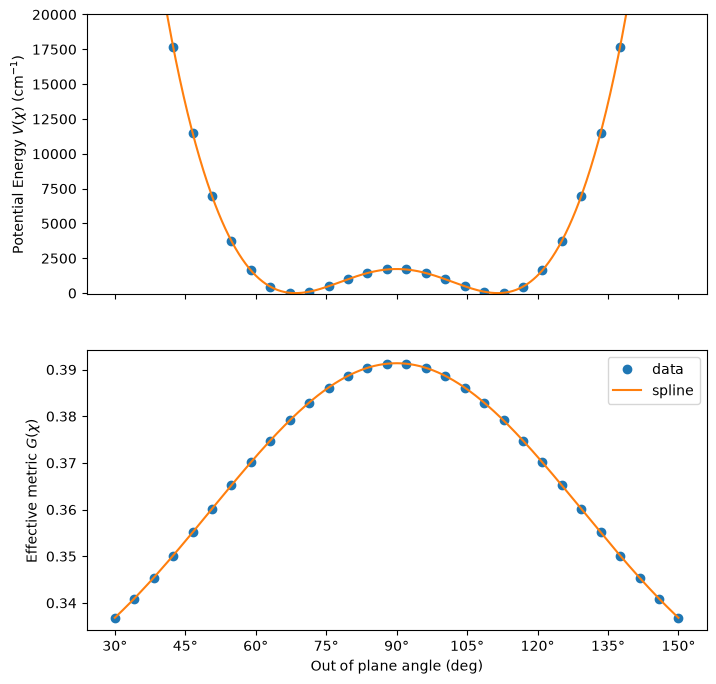

In [7]:
oop_fine = np.linspace(np.min(oop_scan), np.max(oop_scan), 1000)
pot_fine = pot_spline(oop_fine)
metric_fine = metric_spline(oop_fine)

fig, ax = plt.subplots(2, 1, figsize=(8, 8), sharex=True)
xticks = np.arange(30, 151, 15)
ax[0].set_xticks(xticks)
ax[0].set_xticklabels([f'{int(t)}°' for t in xticks], fontsize=12)
ax[0].plot(oop_scan / np.pi * 180, (pot - pot_eq) / CmInv, 'o', label='data')
ax[0].plot(oop_fine / np.pi * 180, (pot_fine - pot_eq) / CmInv, '-', label='spline')
ax[0].set_ylim(-100, 20000)
ax[0].set_ylabel(r'Potential Energy $V(\chi)$ (cm$^{-1}$)')
ax[1].plot(oop_scan / np.pi * 180, metric, 'o', label='data')
ax[1].plot(oop_fine / np.pi * 180, metric_fine, '-', label='spline')
ax[1].set_xlabel('Out of plane angle (deg)')
ax[1].set_ylabel(r'Effective metric $G(\chi)$')
plt.legend()
plt.show()

## Calculation of spectra

`run` computes the spectra by the following steps for each trajectory:

1. Propagate the trajectory by `ImplicitVerlet` in the physical space.
2. Propagate the variation and compute the monodromy matrix.
3. Exclude the steps where the symplectic condition is not satisfied.
4. Compute the action, the prefactor and the overlap with each initial state, and the spectrum by the FFT.

In addition to the original initial state $\ket{\Psi} = \ket{\chi_{\text{ref}}, p_{\text{ref}}}$, the spectra are computed for the symmetrized and antisymmetrized states

\begin{align*}
\ket{\Psi_{\pm}} = \ket{\chi_{\text{ref}}, p_{\text{ref}}} \pm \ket{\pi-\chi_{\text{ref}}, -p_{\text{ref}}}.
\end{align*}

which contain only the levels with even and odd parity under the inversion, respectively. Since the amplitude is linear in the initial state, only the overlap with the mirror state is additionally required.

In [8]:
ACTIVE_IDX = np.array([oop_idx])
TOPOLOGIES = [topology] # I-
POSI_EQ = np.array([posi_eq])
ENER_EQ = pot_eq

METRIC_FUNC = lambda q: metric_spline(q).reshape(1, 1) # must return a 2D array
POTENTIAL_FUNC = lambda q: pot_spline(q)[0] # must return a scalar value

SKEW = np.block(
    [[np.zeros((len(ACTIVE_IDX), len(ACTIVE_IDX))), np.eye(len(ACTIVE_IDX))],
     [-np.eye(len(ACTIVE_IDX)), np.zeros((len(ACTIVE_IDX), len(ACTIVE_IDX)))]]
)

def run(posi_sample_list, mome_sample_list,
        posi_ref_list, mome_ref_list, gamma_ref_list, fpath_list,
        dt, n_step, n_fft, symp_err_tol=1e-2):

    # Judge function to check if the point is singular or not
    judge_func = lambda symp_err: np.isfinite(symp_err) & (symp_err < symp_err_tol)

    n_sample = len(mome_sample_list)
    n_ref = len(mome_ref_list)
    spectra = [0.0] * n_ref
    spectra_sym = [0.0] * n_ref
    spectra_asym = [0.0] * n_ref
    vari_propagator = make_vari_propagator_implicit(METRIC_FUNC, dt,
                                                    potential_func=POTENTIAL_FUNC, normalize=False)

    t_start = time.perf_counter()
    for i in range(n_sample):
        # Get trajectory
        traj = ImplicitVerlet(posi_sample_list[i], mome_sample_list[i], dt, METRIC_FUNC,
                              potential_func=POTENTIAL_FUNC, normalize=False).run(n_step)
        posi, mome = traj["posi"], traj["mome"]

        # Get variation
        mono_init = np.eye(len(ACTIVE_IDX) * 2)
        mono = propagate_variation_implicit(vari_propagator, posi, mome, traj["mome_half"], mono_init)
        symplectic_error = np.max(np.abs(mono.transpose(0, 2, 1) @ SKEW @ mono - SKEW), axis=(1, 2))

        # Points with large symplectic error are treated as singularities
        valid = judge_func(symplectic_error)

        lag = get_lagrangian(traj["total_energy"], traj["potential_energy"], ener_ref=ENER_EQ)
        action = get_action(lag, dt)

        for j in range(n_ref):
            gamma = gamma_ref_list[j]
            prefactor = get_prefactor(mono, gamma, valid=valid)
            overlap_direct = get_overlap(TOPOLOGIES, posi_ref_list[j], mome_ref_list[j], posi, mome, gamma)
            overlap_mirror = get_overlap(TOPOLOGIES, np.pi - posi_ref_list[j], -mome_ref_list[j], posi, mome, gamma)
            ener_grid, spec = get_ta_spectrum_fft(prefactor, overlap_direct, action, dt, n_fft, valid=valid)
            _, spec_sym = get_ta_spectrum_fft(prefactor, overlap_direct + overlap_mirror, action, dt, n_fft, valid=valid)
            _, spec_asym = get_ta_spectrum_fft(prefactor, overlap_direct - overlap_mirror, action, dt, n_fft, valid=valid)

            spectra[j] += spec
            spectra_sym[j] += spec_sym
            spectra_asym[j] += spec_asym

        if i % 10 == 0:
            print(f"{i+1:6d} / {n_sample}, E = {(traj['total_energy'][-1]-ENER_EQ)/CmInv:.1f} cm^-1, "
                  f"max symp error = {np.max(symplectic_error):.3e}, ({time.perf_counter() - t_start:.1f} sec)", flush=True)

    for j in range(n_ref):
        spectra[j] /= n_sample
        spectra_sym[j] /= n_sample
        spectra_asym[j] /= n_sample

    for j in range(n_ref):
        np.savez(fpath_list[j], ener_grid=ener_grid, spectrum=spectra[j],
                 spectrum_sym=spectra_sym[j], spectrum_asym=spectra_asym[j])

## Execute calculation

The total propagation time is 5 ps (10000 steps of 0.5 fs), and 200 trajectories are sampled up to the kinetic energy of 10000 $\textrm{cm}^{-1}$.

In [9]:
if __name__ == "__main__":
    N_SAMPLE = 200
    K_MAX = 10000.0 # cm^-1
    metric_eq = metric_spline(POSI_EQ)

    posi_sample_list = np.repeat([POSI_EQ], N_SAMPLE, axis=0)
    mome_max = np.sqrt(2 * K_MAX * CmInv / metric_spline(POSI_EQ))
    # G p^2/2 = K
    mome_sample_list = np.linspace(mome_max / N_SAMPLE, mome_max, N_SAMPLE)[:, None]

    K_ref_list = np.array([1000, 2000, 3000, 4000, 5000])
    posi_ref_list = np.repeat([POSI_EQ], len(K_ref_list), axis=0)
    mome_ref_list = np.sqrt(2 * K_ref_list[:, None] * CmInv / metric_eq)
    gamma_ref_list = np.repeat([[12.5]], len(K_ref_list), axis=0)
    fpath_list = [f"ammonia_oop_{k:.0f}_spectra.npz" for k in K_ref_list]
    dt = 0.1 * FemtoSec
    n_step = 10000
    n_fft = 2 ** 19

    run(posi_sample_list, mome_sample_list,
        posi_ref_list, mome_ref_list, gamma_ref_list, fpath_list,
        dt, n_step, n_fft)

     1 / 200, E = 0.3 cm^-1, max symp error = 1.743e-14, (0.6 sec)
    11 / 200, E = 30.3 cm^-1, max symp error = 1.610e-14, (2.9 sec)
    21 / 200, E = 110.2 cm^-1, max symp error = 3.053e-14, (5.3 sec)
    31 / 200, E = 240.3 cm^-1, max symp error = 2.953e-14, (7.9 sec)
    41 / 200, E = 420.3 cm^-1, max symp error = 8.260e-14, (10.4 sec)
    51 / 200, E = 650.3 cm^-1, max symp error = 9.748e-14, (13.0 sec)
    61 / 200, E = 930.3 cm^-1, max symp error = 9.293e-14, (15.5 sec)
    71 / 200, E = 1260.3 cm^-1, max symp error = 2.662e-13, (18.1 sec)
    81 / 200, E = 1640.4 cm^-1, max symp error = 3.655e-11, (20.6 sec)
    91 / 200, E = 2070.4 cm^-1, max symp error = 1.030e-11, (23.2 sec)
   101 / 200, E = 2550.5 cm^-1, max symp error = 3.282e-12, (25.7 sec)
   111 / 200, E = 3080.5 cm^-1, max symp error = 1.919e-12, (28.2 sec)
   121 / 200, E = 3660.6 cm^-1, max symp error = 1.429e-12, (30.8 sec)
   131 / 200, E = 4290.2 cm^-1, max symp error = 1.743e-12, (33.3 sec)
   141 / 200, E = 49

## DVR reference

The reference eigenenergies of the 1D Hamiltonian are obtained by the DVR method using sine bases.

First 16 DVR eigenenergies (cm^-1): [ 508.  510. 1383. 1460. 2013. 2397. 2924. 3489. 4101. 4752. 5437. 6153. 6898. 7669. 8464. 9282.]


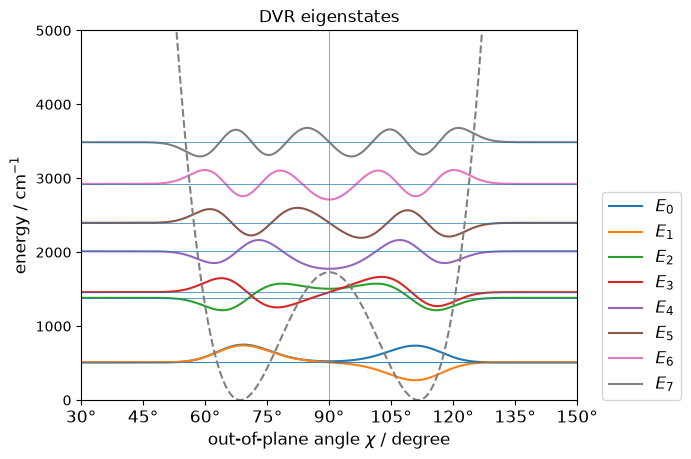

In [10]:
def dvr_1d_sine(a, b, N, K, cs_g, cs_V):

    L = b - a
    chi = a + L * (np.arange(N) + 0.5) / N
    w = L / N
    n = np.arange(1, K + 1)
    arg = np.outer(chi - a, n) * np.pi / L
    X = np.sqrt(2 / L) * np.sin(arg) # chi_n(chi_j)
    dX = np.sqrt(2 / L) * (n * np.pi / L) * np.cos(arg) # chi_n'(chi_j)

    g = cs_g(chi)
    gm14 = g ** -0.25
    dgm14 = -0.25 * cs_g(chi, 1) * g ** -1.25

    U = dgm14[:, None] * X + gm14[:, None] * dX # d/dchi [g^{-1/4} chi_n]
    T = 0.5 * HBar**2 * w * (U.T @ (g[:, None] ** -0.5 * U))
    Vm = w * (X.T @ ((cs_V(chi)[:, None]) * X))
    H = T + Vm
    H = (H + H.T) / 2
    return np.linalg.eigvalsh(H), H

if __name__ == "__main__":
    a = oop_scan[0]
    b = oop_scan[-1]
    N, K = 401, 200
    cs_g = CubicSpline(oop_scan, 1.0 / metric)
    cs_V = CubicSpline(oop_scan, pot - pot_eq)
    E, H = dvr_1d_sine(a, b, N, K, cs_g, cs_V)
    _, C = np.linalg.eigh(H) # get eigenvectors of the Hamiltonian

    E_dvr = E / CmInv
    print(f"First 16 DVR eigenenergies (cm^-1): {np.round(E_dvr[:16], 0)}")

    L = b - a
    chi_p = np.linspace(a, b, 1000)
    n_b = np.arange(1, K + 1)
    X_p = np.sqrt(2 / L) * np.sin(np.outer(chi_p - a, n_b) * np.pi / L) # Sine basis

    for i, n in enumerate(range(8)):
        psi_t = X_p @ C[:, n]  # amplitude w.r.t. d(phi)
        y = psi_t * 150 + E[n] / CmInv # signed amplitude shows the parity
        plt.plot(np.degrees(chi_p), y, label=f'$E_{{{n}}}$')
        plt.hlines(E[n] / CmInv, np.degrees(a), np.degrees(b), lw=0.5)

    plt.title("DVR eigenstates")
    plt.plot(np.degrees(chi_p), (cs_V(chi_p)) / CmInv, ls='dashed', c='gray')
    plt.axvline(90, c='gray', lw=0.5)
    xticks = np.arange(30, 151, 15)
    plt.xticks(xticks, labels=[f'{int(t)}°' for t in xticks], fontsize=12)
    plt.xlim(np.degrees(a), np.degrees(b))
    plt.ylim(0, 5000)
    plt.legend(loc=(1.05, 0), fontsize=12)
    plt.xlabel(r'out-of-plane angle $\chi$ / degree', fontsize=12)
    plt.ylabel(r'energy / cm$^{-1}$', fontsize=12)
    plt.show()

DVR eigenenergies (cm^-1): [ 508.  510. 1383. 1460. 2013. 2397. 2924. 3489. 4101. 4752. 5437. 6153. 6898. 7669. 8464. 9282.]
Peaks (cm^-1) for K = 1000: [ 520. 1446. 1951. 2398. 2915.]
Peaks (cm^-1) for K = 2000: [1444. 1949. 2397. 2913. 3481. 4093. 4747.]
Peaks (cm^-1) for K = 3000: [2395. 2911. 3480. 4093. 4744. 5430.]
Peaks (cm^-1) for K = 4000: [3480. 4093. 4744. 5430. 6147. 6892.]
Peaks (cm^-1) for K = 5000: [4092. 4744. 5430. 6147. 6892. 7663. 8458.]


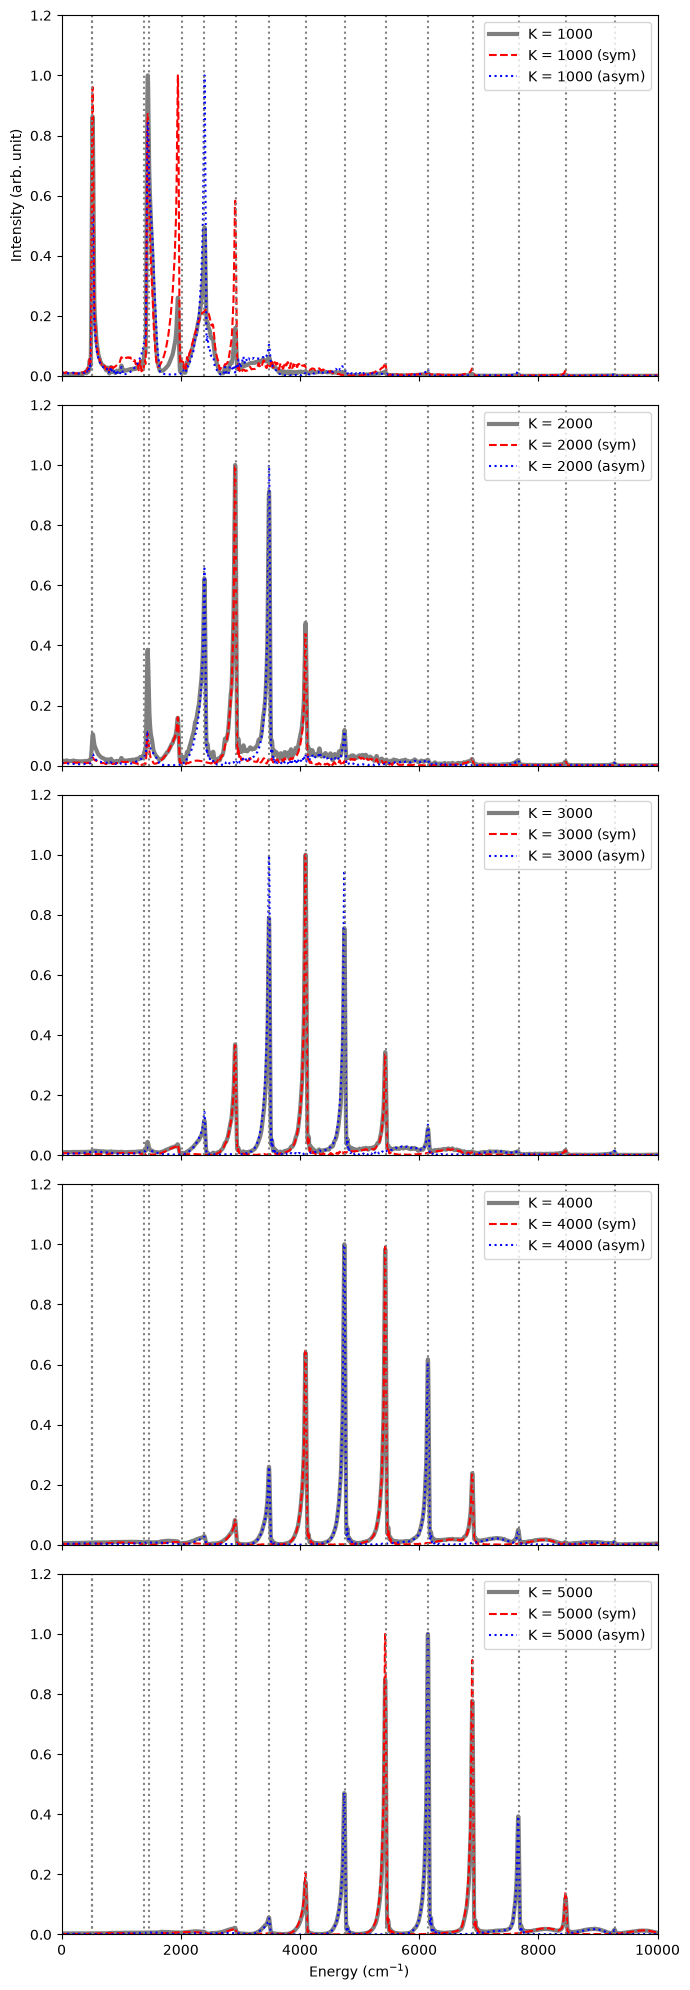

In [11]:
if __name__ == "__main__":
    import matplotlib.pyplot as plt
    from scipy.signal import find_peaks

    fpath_list = [f"ammonia_oop_{k:.0f}_spectra.npz" for k in K_ref_list]
    fig, ax = plt.subplots(5, 1, figsize=(7, 5 * 4), sharex=True)
    dvr_ref = E_dvr[:16]
    print(f"DVR eigenenergies (cm^-1): {np.round(dvr_ref, 0)}")

    for i, fpath in enumerate(fpath_list):
        data = np.load(fpath)
        ener_grid = data["ener_grid"] / CmInv
        spectrum = data["spectrum"]
        spectrum /= np.max(spectrum[ener_grid <= 10000])
        spectrum_sym = data["spectrum_sym"]
        spectrum_sym /= np.max(spectrum_sym[ener_grid <= 10000])
        spectrum_asym = data["spectrum_asym"]
        spectrum_asym /= np.max(spectrum_asym[ener_grid <= 10000])
        peaks, _ = find_peaks(spectrum, height=0.1, prominence=0.1)
        peaks = peaks[ener_grid[peaks] <= 10000]
        print(f"Peaks (cm^-1) for K = {K_ref_list[i]:.0f}: {np.round(ener_grid[peaks], 0)}")
 
        ax[i].plot(ener_grid, spectrum, label=f"K = {K_ref_list[i]:.0f}", color='black', linewidth=3, alpha=0.5)
        ax[i].plot(ener_grid, spectrum_sym, label=f"K = {K_ref_list[i]:.0f} (sym)", color='red', linestyle="--")
        ax[i].plot(ener_grid, spectrum_asym, label=f"K = {K_ref_list[i]:.0f} (asym)", color='blue', linestyle=":")
        ax[i].vlines(dvr_ref, 0, 1.2, color='gray', linestyle=":")
        ax[i].set_ylim(0, 1.2)
        ax[i].legend()
 
    ax[-1].set_xlim(0, 10000)
    ax[-1].set_xlabel("Energy (cm$^{-1}$)")
    ax[0].set_ylabel("Intensity (arb. unit)")
    plt.tight_layout()
    plt.show()

The levels are labeled as $v^{\pm}$, where $v^{+}$ and $v^{-}$ denote the lower (symmetric) and upper (antisymmetric) levels of the tunneling doublet originating from the $v$-th vibrational level of each well, respectively.

Above the barrier, the doublet structure is lost and the levels form a single ladder, but the same labels are used conventionally.

The symmetric and antisymmetric spectra are used to assign the parity of each peak (all in $\textrm{cm}^{-1}$).

| Level | $E$ (SC-IVR) | $E$ (DVR) | $E$ (SC-IVR) $-$ $E$ (DVR) |
|---|---|---|---|
| $0^{\pm}$ | 520 | 508 / 510 | +12 / +10 |
| $1^{\pm}$ | 1445 | 1383 / 1460 | +62 / -15 |
| $2^{+}$ / $2^{-}$ | 1950 / 2396 | 2013 / 2397 | -63 / -1 |
| $3^{+}$ / $3^{-}$ | 2912 / 3480 | 2924 / 3489 | -12 / -9 |
| $4^{+}$ / $4^{-}$ | 4093 / 4744 | 4101 / 4752 | -8 / -8 |
| $5^{+}$ / $5^{-}$ | 5430 / 6147 | 5437 / 6153 | -7 / -6 |
| $6^{+}$ / $6^{-}$ | 6892 / 7663 | 6898 / 7669 | -6 / -6 |
| $7^{+}$ | 8457 | 8464 | -7 |

- **Tunneling splitting**: The barrier of this system (1729 $\textrm{cm}^{-1}$) is not high: it is only about three times the zero-point energy (about 500 $\textrm{cm}^{-1}$). Therefore, even the low-lying levels localized in the two wells are mixed by tunneling through the barrier, and each level splits into the symmetric and antisymmetric levels. The splitting is small for $0^{\pm}$ (2 $\textrm{cm}^{-1}$) but becomes significant for $1^{\pm}$ (77 $\textrm{cm}^{-1}$), which lies just below the barrier.

- **High-energy levels**: Well above the barrier ($3^{\pm}$ and higher), the differences from the DVR levels are almost constant (about −7 $\textrm{cm}^{-1}$), i.e., the levels are uniformly shifted by a constant energy offset, and the level spacings are reproduced within a few $\textrm{cm}^{-1}$.

- **Levels near and below the barrier**: In the present one-dimensional model, SC-IVR gives a single peak for each doublet below the barrier and does not reproduce the tunneling splitting, especially for $1^{\pm}$. The error is also large for $2^{+}$, which lies just above the barrier top. Describing deep tunneling with classical trajectories is a known difficulty of the semiclassical methods (see also References).

**Reference:**

- A. L. Kaledin and W. H. Miller, "Time averaging the semiclassical initial value representation for the calculation of vibrational energy levels. II. Application to H2CO, NH3, CH4, CH2D2,"
*J. Chem. Phys.* **119**, 3078–3084 (2003).

- R. Conte, A. Aspuru-Guzik, and M. Ceotto, "Reproducing Deep Tunneling Splittings, Resonances, and Quantum Frequencies in Vibrational Spectra From a Handful of Direct Ab Initio Semiclassical Trajectories," *J. Phys. Chem. Lett.* **4**, 3407-3412 (2013).